# Prova Pratica 3 - Incertezza & Covarianza

In [55]:
import numpy as np
import matplotlib.pyplot as plt


def print_result(name, value, uncertainty, unit=""):
    print(f"{name} = ({value:.4g} ± {uncertainty:.2g}) {unit}") # utile per stampare risultati


def covariance_to_correlation(cov):
    std = np.sqrt(np.diag(cov))
    return cov / np.outer(std, std)


alpha_hat, u_alpha = 0.91, 0.018
delta_hat, u_delta = 5.18, 0.045
rho_alpha_delta = -0.65

k, u_k = 10.0, 0.10
sx, u_sx = 1.0, 0.005

cov_rad = rho_alpha_delta * u_alpha * u_delta
C_ad = np.array([[u_alpha**2, cov_rad], [cov_rad, u_delta**2]])


# Stampa dei risultati
#print_result("α", alpha_hat, u_alpha, "mm^-1")
#print_result("δ", delta_hat, u_delta, "mm^-1")
#print_result("k", k, u_k, "mm^-2")
#print_result("s_x", sx, u_sx, "mm^-2")



## Attività 1: Costruzione della matrice di covarianza

Simmetria dellla matrice di covarianza: True
Diagonale positiva: True
Autovalori non negativi: True


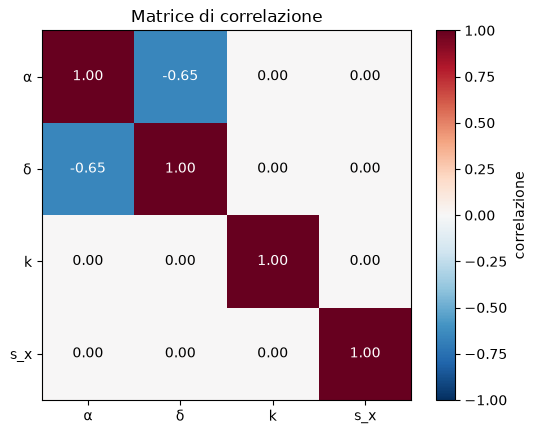

In [56]:
z = np.array([alpha_hat, delta_hat, k, sx])
z_names = ["α", "δ", "k", "s_x"]
C_z = np.array([[u_alpha**2, cov_rad,0,0], 
                [cov_rad, u_delta**2,0,0], 
                [0,0,u_k**2,0], 
                [0,0,0,u_sx**2]])

print(f"Simmetria dellla matrice di covarianza: {np.allclose(C_z, C_z.T)}")
print(f"Diagonale positiva: {np.all(np.diag(C_z)) > 0}")
print(f"Autovalori non negativi: {np.all(np.linalg.eigvalsh(C_z) >= 0)}") # entro il limite numerico?

R_z = covariance_to_correlation(C_z)
r_ad = R_z[0,1]

fig, ax = plt.subplots()
ax.set_title("Matrice di correlazione")
ax.set_xticks(range(len(z_names)), z_names)
ax.set_yticks(range(len(z_names)), z_names)
image = ax.imshow(R_z, vmin=-1, vmax=1, cmap="RdBu_r")

for row in range (len(z_names)):
    for column in range(len(z_names)):
        color = "white" if abs(R_z[row, column]) > 0.5 else "black"
        ax.text(row, column, f"{R_z[row, column]:.2f}", ha="center", va="center", color=color)

fig.colorbar(image, ax=ax, label="correlazione")
plt.show()


## Attività 2: Propagazione Analitica

In [57]:
a = alpha_hat / (k * sx) # a = alpha / k * s_x
d = delta_hat / (k * sx) # d = delta / k * s_x
q = delta_hat / alpha_hat # q = delta / alpha

g_z = np.array([a, d, q])


def jacobian_g(z):
    al, de, k, sx = z
    J = np.array([[1/(k*sx), 0, -al/(k**2*sx), -al/(k*sx**2)],
                  [0, 1/(k*sx), -de/(k**2*sx), -de/(k*sx**2)],
                  [-de/al**2, 1/al, 0,0]])
    return J

def linear_propagation(z, C_z):
    J = jacobian_g(z)
    C_g = J @ C_z @ J.T
    return C_g



R_g = covariance_to_correlation(linear_propagation(z, C_z))

u_a = np.sqrt(linear_propagation(z, C_z)[0,0])
u_d = np.sqrt(linear_propagation(z, C_z)[1,1])
u_q = np.sqrt(linear_propagation(z, C_z)[2,2])


print_result("a", a, u_a, "mm^-1")
print_result("d", d, u_d, "mm^-1")
print_result("q", q, u_q)

print(f"\nMatrice di Covarianza di g(z): \n{np.round(linear_propagation(z, C_z), 4)}") ## andrebbe arrotondata meglio
print(f"\nMatrice di Correlazione di a, d, q: \n{np.round(R_g, 4)}") 

lhs = (u_q/q)**2
rhs = (u_alpha/alpha_hat)**2 + (u_delta/delta_hat)**2 - 2 * (cov_rad/(alpha_hat*delta_hat))

if np.isclose(lhs, rhs):
    print("\nLa condizione sull'incertezza di q è verificata")
else:
    print("\nLa condizione sull'incertezza di q NON è verificata") ## si potrebbe mettere un messaggio di errore?






    
    

a = (0.091 ± 0.0021) mm^-1
d = (0.518 ± 0.0073) mm^-1
q = (5.692 ± 0.15) 

Matrice di Covarianza di g(z): 
[[ 0.      0.     -0.0003]
 [ 0.      0.0001  0.0006]
 [-0.0003  0.0006  0.0224]]

Matrice di Correlazione di a, d, q: 
[[ 1.      0.0414 -0.8426]
 [ 0.0414  1.      0.5032]
 [-0.8426  0.5032  1.    ]]

La condizione sull'incertezza di q è verificata


## Attività 3: Propagazione Montecarlo Correlata

=== Grandezze derivate da campionamento Monte Carlo ===
a: (0.0910 ± 0.0021) mm^-1,
    - mediana = 0.0910,
    - 16% = 0.0890,
    - 84% = 0.0931
d: (0.5181 ± 0.0073) mm^-1,
    - mediana = 0.5180,
    - 16% = 0.5108,
    - 84% = 0.5254
q: (5.6951 ± 0.1498) ,
    - mediana = 5.6928,
    - 16% = 5.5463,
    - 84% = 5.8438


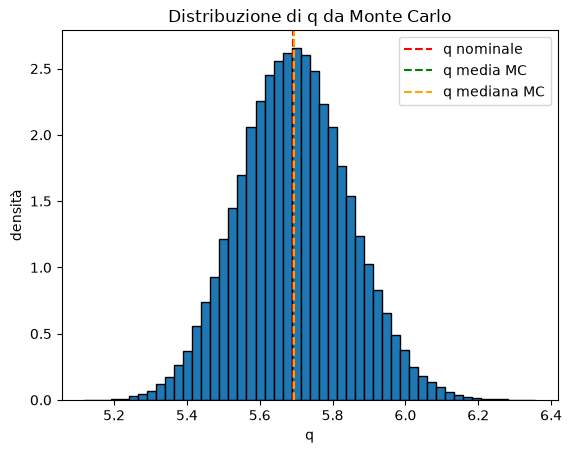

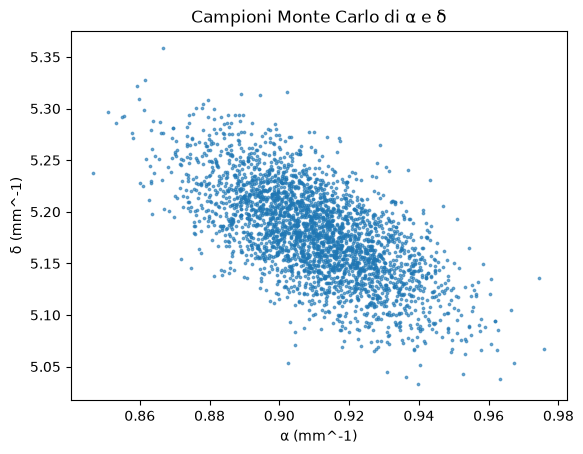

In [ ]:
M = 100_000

rng = np.random.default_rng(20261003)
campioni = rng.multivariate_normal(
    mean=z,
    cov=C_z,
    size=M
)

a_mc = campioni[:, 0] / (campioni[:, 2] * campioni[:, 3])
d_mc = campioni[:, 1] / (campioni[:, 2] * campioni[:, 3])
q_mc = campioni[:, 1] / campioni[:, 0]

#verifica ammissibilità??

def print_mc_results(name, value, unit=""):
    mc_mean = np.mean(value)
    mc_std = np.std(value,ddof=1)
    mc_median = np.median(value)
    mc_percentile = np.percentile(value, [16, 84])
    
    print(f"""{name}: ({mc_mean:.4f} ± {mc_std:.4f}) {unit},
    - mediana = {mc_median:.4f},
    - 16% = {mc_percentile[0]:.4f},
    - 84% = {mc_percentile[1]:.4f}""")


print("=== Grandezze derivate da campionamento Monte Carlo ===")
print_mc_results("a", a_mc, "mm^-1")
print_mc_results("d", d_mc, "mm^-1")
print_mc_results("q", q_mc)

u_q_mc = np.std(q_mc, ddof=1)


plt.figure()
plt.hist(q_mc, bins=50, density=True, edgecolor="black")
plt.axvline(q, color="red", linestyle="--", label="q nominale")
plt.axvline(np.mean(q_mc), color="green", linestyle="--", label="q media MC")
plt.axvline(np.median(q_mc), color="orange", linestyle="--", label="q mediana MC")
plt.xlabel("q")
plt.ylabel("densità")
plt.title("Distribuzione di q da Monte Carlo")
plt.legend()
plt.show()

plt.figure()
plt.scatter(campioni[:3000,0], campioni[:3000,1], alpha=0.6, s=3)
plt.xlabel("α (mm^-1)")
plt.ylabel("δ (mm^-1)")
plt.title("Correlazione campioni Monte Carlo di α e δ")
plt.show()
